# GEM-NES 2021 | Entrepreneurial Ecosystems Analysis

**Countries:** United States, South Africa, Sudan  
**Source:** Global Entrepreneurship Monitor — National Expert Survey (NES), 2021  

This notebook documents the data preparation, entrepreneurial framework condition scoring, visualizations, and interactive dashboard creation. To rerun it, the original GEM NES 2021 SPSS (`.sav`) dataset must be uploaded to the Colab working directory.


In [1]:
import pandas as pd

In [2]:
import pandas as pd
import numpy as np

In [3]:
%pip install pyreadstat

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 27.7 MB/s  0:00:00


In [4]:
df=pd.read_spss("/content/GEM 2021 NES GLOBAL INDIVIDUAL LEVEL NATIONS.sav")

In [5]:
df.head(10)

,NES_COUNTRY,START_DATE,END_DATE,ENDED,TENPOINTS,NES21_A01,NES21_A02,NES21_A03,NES21_A04,NES21_A05,...,ZNES_CSUM5,ZNES_D1SUM5,ZNES_D2SUM5,ZNES_ESUM5,ZNES_FSUM5,ZNES_G1SUM5,ZNES_G2SUM5,ZNES_HSUM5,ZNES_ISUM5,ENDSECTION5
0,USA,NaN,2021-08-08 15:55:33,Respondent went to end of survey,NaN,Completely true,Completely true,Completely true,Completely true,Completely true,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.006338,NaN
1,USA,NaN,2021-07-12 16:11:10,Respondent went to end of survey,NaN,8.0,4.0,2.0,9.0,9.0,...,-0.646455,-0.837643,-0.165633,1.046357,1.549851,-0.051829,0.068120,NaN,-0.172634,NaN
2,USA,NaN,2021-06-01 19:58:45,Respondent went to end of survey,NaN,Neither true nor false,3.0,4.0,2.0,3.0,...,-0.486616,0.180651,0.856753,-0.599086,-0.627495,-0.051829,-0.830865,-1.140856,1.010517,NaN
3,USA,NaN,2021-07-12 17:44:49,Respondent went to end of survey,NaN,Neither true nor false,8.0,8.0,8.0,3.0,...,-0.643460,-0.496256,-0.872829,-1.141263,0.957064,-0.977450,-0.830865,1.268370,1.010517,NaN
4,USA,NaN,2021-04-30 12:53:19,Respondent went to end of survey,NaN,4.0,1.0,1.0,6.0,Completely false,...,-0.886775,-1.170230,0.843290,NaN,NaN,1.799413,-1.963958,NaN,1.192001,NaN
5,USA,NaN,2021-06-02 13:14:58,Respondent went to end of survey,NaN,8.0,6.0,3.0,8.0,7.0,...,0.284317,0.192385,0.174898,0.497728,1.160479,-0.051829,0.915316,0.391622,1.010517,NaN
6,USA,NaN,2021-07-12 19:53:53,Respondent went to end of survey,NaN,Neither true nor false,6.0,3.0,6.0,NaN,...,NaN,-0.151936,0.844082,0.847907,1.157696,0.873792,0.564680,0.766123,1.010517,NaN
7,USA,NaN,2021-06-02 08:02:43,Respondent went to end of survey,NaN,7.0,7.0,Neither true nor false,7.0,7.0,...,NaN,1.884653,2.232341,NaN,1.142010,0.873792,0.042225,NaN,1.819709,NaN
8,USA,NaN,2021-07-22 03:55:41,Respondent went to end of survey,NaN,9.0,4.0,7.0,9.0,9.0,...,NaN,-0.837643,-1.566563,0.137092,0.948462,0.873792,0.328123,1.080883,-0.574658,NaN
9,USA,NaN,2021-08-02 20:14:22,Respondent went to end of survey,NaN,4.0,Neither true nor false,NaN,6.0,Neither true nor false,...,0.100334,-0.151936,0.149557,NaN,NaN,-0.977450,NaN,0.078515,1.010517,NaN


In [6]:
df.tail(10)

,NES_COUNTRY,START_DATE,END_DATE,ENDED,TENPOINTS,NES21_A01,NES21_A02,NES21_A03,NES21_A04,NES21_A05,...,ZNES_CSUM5,ZNES_D1SUM5,ZNES_D2SUM5,ZNES_ESUM5,ZNES_FSUM5,ZNES_G1SUM5,ZNES_G2SUM5,ZNES_HSUM5,ZNES_ISUM5,ENDSECTION5
2066,Jamaica,2021-05-20 12:54:30,2021-05-20 13:30:25,Respondent went to end of survey,NaN,Neither true nor false,7.0,4.0,Neither true nor false,4.0,...,NaN,1.884653,1.879138,0.484379,-0.841030,0.873792,0.915316,-2.032480,1.010517,NaN
2067,Jamaica,2021-05-18 19:05:47,2021-05-18 19:44:26,Respondent went to end of survey,NaN,2.0,7.0,Neither true nor false,3.0,4.0,...,-0.634851,-0.505057,-0.191767,-0.782629,-1.453044,-0.977450,-1.963958,-0.107555,-0.794496,NaN
2068,Jamaica,2021-06-19 12:13:51,2021-06-19 12:49:31,Respondent went to end of survey,NaN,8.0,4.0,2.0,6.0,6.0,...,-0.935812,-0.151936,0.490880,-0.417544,0.736951,-0.977450,NaN,-0.797761,0.812663,NaN
2069,Jamaica,2021-05-18 13:08:57,2021-05-18 13:24:57,Respondent went to end of survey,NaN,Neither true nor false,9.0,Neither true nor false,Neither true nor false,Neither true nor false,...,-1.528189,-1.170230,0.502759,-0.405308,0.568451,-0.051829,-0.570863,-0.829874,1.010517,NaN
2070,Jamaica,2021-06-21 08:42:31,2021-06-21 09:03:02,Respondent went to end of survey,NaN,8.0,7.0,Neither true nor false,6.0,8.0,...,-0.641776,0.866358,1.197284,0.860811,1.546309,0.873792,1.461216,0.937553,1.197380,NaN
2071,Jamaica,2021-05-29 17:20:41,2021-05-29 17:36:29,Respondent went to end of survey,NaN,2.0,3.0,2.0,3.0,2.0,...,-0.156083,NaN,-0.190183,-1.144155,0.193754,-1.440261,-0.596758,-0.474736,0.992743,NaN
2072,Jamaica,2021-05-30 22:39:28,2021-05-30 23:24:19,Respondent went to end of survey,NaN,2.0,2.0,2.0,2.0,4.0,...,-0.935812,-0.149002,-0.872829,-0.599086,-0.280121,0.410982,NaN,-0.938258,-0.788181,NaN
2073,Jamaica,2021-05-30 11:13:38,2021-05-30 12:02:15,Respondent went to end of survey,NaN,2.0,6.0,1.0,3.0,1.0,...,NaN,-0.493323,-0.179888,-0.600420,0.003748,-0.051829,-0.830865,-0.803900,1.405992,NaN
2074,Jamaica,2021-05-31 13:18:43,2021-05-31 13:43:25,Respondent went to end of survey,NaN,Completely false,Completely false,Completely false,Completely false,Completely false,...,0.568620,0.854624,-0.872829,-1.332149,1.163515,-1.903071,-0.570863,0.949123,0.776647,NaN
2075,Jamaica,2021-05-28 13:56:25,2021-05-28 17:36:28,Respondent went to end of survey,NaN,Neither true nor false,4.0,NaN,NaN,NaN,...,NaN,-0.837643,NaN,NaN,NaN,NaN,NaN,-3.244531,-0.414690,NaN


In [7]:
df.columns

Index(['NES_COUNTRY', 'START_DATE', 'END_DATE', 'ENDED', 'TENPOINTS',
       'NES21_A01', 'NES21_A02', 'NES21_A03', 'NES21_A04', 'NES21_A05',
       ...
       'ZNES_CSUM5', 'ZNES_D1SUM5', 'ZNES_D2SUM5', 'ZNES_ESUM5', 'ZNES_FSUM5',
       'ZNES_G1SUM5', 'ZNES_G2SUM5', 'ZNES_HSUM5', 'ZNES_ISUM5',
       'ENDSECTION5'],
      dtype='object', length=721)

In [8]:
import os

os.listdir("/content")

['.config', 'GEM 2021 NES GLOBAL INDIVIDUAL LEVEL NATIONS.sav', 'sample_data']

In [9]:
import pyreadstat
import pandas as pd

df, meta = pyreadstat.read_sav(
    "/content/GEM 2021 NES GLOBAL INDIVIDUAL LEVEL NATIONS.sav"
)

variables = pd.DataFrame({
    "Variable": meta.column_names,
    "Description": meta.column_labels
})

print("Nombre de variables :", len(variables))

variables.head(20)

Nombre de variables : 721


,Variable,Description
0,NES_COUNTRY,"country phone code (up to 4 digits), countryal..."
1,START_DATE,StartDate
2,END_DATE,EndDate
3,ENDED,Finished
4,TENPOINTS,VARIABLES EXPRESSED IN 0-10 POINTS SCALES (CLO...
5,NES21_A01,In my country there is sufficient: equity fund...
6,NES21_A02,In my country there is sufficient: debt fundin...
7,NES21_A03,In my country there is sufficient: government ...
8,NES21_A04,In my country there is sufficient: informal in...
9,NES21_A05,In my country there is sufficient: professiona...


In [10]:
print("Nombre de pays :", df["NES_COUNTRY"].nunique())

print("\nPays disponibles :")
print(sorted(df["NES_COUNTRY"].dropna().unique()))

Nombre de pays : 50

Pays disponibles :
[np.float64(1.0), np.float64(7.0), np.float64(20.0), np.float64(27.0), np.float64(30.0), np.float64(31.0), np.float64(33.0), np.float64(34.0), np.float64(36.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(44.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(52.0), np.float64(55.0), np.float64(56.0), np.float64(57.0), np.float64(81.0), np.float64(82.0), np.float64(90.0), np.float64(91.0), np.float64(98.0), np.float64(101.0), np.float64(212.0), np.float64(249.0), np.float64(352.0), np.float64(353.0), np.float64(357.0), np.float64(358.0), np.float64(370.0), np.float64(371.0), np.float64(375.0), np.float64(385.0), np.float64(386.0), np.float64(421.0), np.float64(502.0), np.float64(507.0), np.float64(598.0), np.float64(701.0), np.float64(966.0), np.float64(968.0), np.float64(971.0), np.float64(972.0), np.float64(974.0), np.float64(1767.0), np.float64(1876.0)]


In [11]:
pays = sorted(df["NES_COUNTRY"].dropna().unique())

for pays_nom in pays:
    print(pays_nom)

1.0
7.0
20.0
27.0
30.0
31.0
33.0
34.0
36.0
39.0
40.0
41.0
44.0
46.0
47.0
48.0
49.0
52.0
55.0
56.0
57.0
81.0
82.0
90.0
91.0
98.0
101.0
212.0
249.0
352.0
353.0
357.0
358.0
370.0
371.0
375.0
385.0
386.0
421.0
502.0
507.0
598.0
701.0
966.0
968.0
971.0
972.0
974.0
1767.0
1876.0


In [12]:
codes_pays = meta.variable_value_labels.get("NES_COUNTRY", {})

print("Correspondance entre codes et pays :")

for code, nom in sorted(codes_pays.items()):
    print(code, ":", nom)

Correspondance entre codes et pays :
1.0 : USA
7.0 : Russia
20.0 : Egypt
27.0 : South Africa
30.0 : Greece
31.0 : Netherlands
32.0 : Belgium
33.0 : France
34.0 : Spain
36.0 : Hungary
39.0 : Italy
40.0 : Romania
41.0 : Switzerland
43.0 : Austria
44.0 : United Kingdom
45.0 : Denmark
46.0 : Sweden
47.0 : Norway
48.0 : Poland
49.0 : Germany
51.0 : Peru
52.0 : Mexico
53.0 : Cuba
54.0 : Argentina
55.0 : Brazil
56.0 : Chile
57.0 : Colombia
58.0 : Venezuela
60.0 : Malaysia
61.0 : Australia
62.0 : Indonesia
63.0 : Philippines
64.0 : New Zealand
65.0 : Singapore
66.0 : Thailand
81.0 : Japan
82.0 : South Korea
84.0 : Vietnam
86.0 : China (PRC)
90.0 : Turkey
91.0 : India
92.0 : Pakistan
93.0 : Afghanistan
94.0 : Sri Lanka
95.0 : Myanmar
97.0 : Do not know
98.0 : Iran
99.0 : Data missing
101.0 : Canada
212.0 : Morocco
213.0 : Algeria
216.0 : Tunisia
218.0 : Libya
220.0 : Gambia
221.0 : Senegal
222.0 : Mauritania
223.0 : Mali Republic
224.0 : Guinea
225.0 : CÃ´te dIvoire
226.0 : Burkina Faso
227.0 :

In [13]:
pays_presents = df["NES_COUNTRY"].dropna().unique()

noms_pays = [
    codes_pays.get(code, f"Code {code}")
    for code in pays_presents
]

print("Nombre de pays :", len(noms_pays))

for pays in sorted(noms_pays):
    print(pays)

Nombre de pays : 50
Belarus
Brazil
Canada
Chile
Colombia
Croatia
Cyprus
Dominica
Egypt
Finland
France
Germany
Greece
Guatemala
Hungary
India
Iran
Ireland
Israel
Italy
Jamaica
Japan
Kazakhstan
Latvia
Lithuania
Luxembourg
Mexico
Morocco
Netherlands
Norway
Oman
Panama
Poland
Qatar
Romania
Russia
Saudi Arabia
Slovak Republic
Slovenia
South Africa
South Korea
Spain
Sudan
Sweden
Switzerland
Turkey
USA
United Arab Emirates
United Kingdom
Uruguay


In [14]:
pays = ["USA", "South Africa", "Sudan"]

for pays_nom in pays:
    codes = [
        code for code, nom in codes_pays.items()
        if nom == pays_nom
    ]
    n = df["NES_COUNTRY"].isin(codes).sum()
    print(f"{pays_nom} : {n} experts")

USA : 48 experts
South Africa : 37 experts
Sudan : 36 experts


In [15]:
variables[variables["Variable"].str.startswith("NES21_")].head(40)

,Variable,Description
5,NES21_A01,In my country there is sufficient: equity fund...
6,NES21_A02,In my country there is sufficient: debt fundin...
7,NES21_A03,In my country there is sufficient: government ...
8,NES21_A04,In my country there is sufficient: informal in...
9,NES21_A05,In my country there is sufficient: professiona...
10,NES21_A06,In my country there is sufficient: venture cap...
11,NES21_A07,In my country there is sufficient: IPO (initia...
12,NES21_A08,In my country there is sufficient: micro fundi...
13,NES21_A09,In my country it is easy: to get debt funding ...
14,NES21_A10,In my country it is easy: to hire financial su...


In [16]:
variables[
    variables["Variable"].str.startswith("NES21_")
].iloc[40:100]

,Variable,Description
45,NES21_F02,"In my country, new and growing firms can affor..."
46,NES21_F03,"In my country, it is easy for new and growing ..."
47,NES21_F04,"In my country, it is easy for new and growing ..."
48,NES21_F05,"In my country, it is easy for new and growing ..."
49,NES21_F06,"In my country, new and growing firms can get a..."
50,NES21_G01,"In my country, the markets for consumer goods ..."
51,NES21_G02,"In my country, the markets for business-to-bus..."
52,NES21_G03,"In my country, new and growing firms can easil..."
53,NES21_G04,"In my country, the new and growing firms can a..."
54,NES21_G05,"In my country, new and growing firms can enter..."


In [17]:
print("Valeurs observées :")
print(df["NES21_A01"].value_counts(dropna=False).sort_index())

print("\nÉtiquettes SPSS :")
print(meta.variable_value_labels.get("NES21_A01", {}))

Valeurs observées :
NES21_A01
0.0      86
1.0      82
2.0     233
3.0     334
4.0     264
5.0     274
6.0     250
7.0     228
8.0     171
9.0      46
10.0     52
NaN      56
Name: count, dtype: int64

Étiquettes SPSS :
{0.0: 'Completely false', 5.0: 'Neither true nor false', 10.0: 'Completely true', 97.0: 'Do not know', 98.0: 'Does not apply', 99.0: 'Data missing'}


In [18]:
codes_selectionnes = [
    code for code, nom in codes_pays.items()
    if nom in ["USA", "South Africa", "Sudan"]
]

df_3pays = df[df["NES_COUNTRY"].isin(codes_selectionnes)].copy()

df_3pays["Pays"] = df_3pays["NES_COUNTRY"].map(codes_pays)

print(df_3pays["Pays"].value_counts())
print("Dimensions :", df_3pays.shape)

Pays
USA             48
South Africa    37
Sudan           36
Name: count, dtype: int64
Dimensions : (121, 722)


In [19]:
import re

colonnes_efc = [
    col for col in df_3pays.columns
    if re.fullmatch(r"NES21_[A-I]\d{2}(?:_2)?", col)
]

print("Nombre de variables :", len(colonnes_efc))

print("\nValeurs manquantes par pays :")
print(
    df_3pays.groupby("Pays")[colonnes_efc]
    .apply(lambda x: x.isna().sum().sum())
)

Nombre de variables : 63

Valeurs manquantes par pays :
Pays
South Africa     76
Sudan            64
USA             522
dtype: int64


In [20]:
manquantes_usa = (
    df_3pays[df_3pays["Pays"] == "USA"][colonnes_efc]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

print(manquantes_usa.head(15))

NES21_C02    24
NES21_E04    21
NES21_C01    17
NES21_E01    17
NES21_C05    16
NES21_C03    15
NES21_C06    15
NES21_C04    14
NES21_E05    14
NES21_E06    13
NES21_H07    12
NES21_A03    12
NES21_B04    11
NES21_E02    11
NES21_A10    10
dtype: int64


In [21]:
import pandas as pd

codes_speciaux = (
    df_3pays[colonnes_efc]
    .isin([97, 98, 99])
    .sum()
)

print(codes_speciaux[codes_speciaux > 0])

Series([], dtype: int64)


In [22]:
dimensions = {
    "A": "Financement",
    "B": "Politiques publiques",
    "C": "Programmes publics",
    "D": "Education",
    "E": "Transfert R&D",
    "F": "Services professionnels",
    "G": "Acces aux marches",
    "H": "Infrastructures physiques",
    "I": "Culture entrepreneuriale"
}

for code, nom in dimensions.items():
    colonnes = [
        col for col in colonnes_efc
        if col.startswith(f"NES21_{code}")
    ]

    df_3pays[nom] = df_3pays[colonnes].mean(axis=1)

scores = df_3pays.groupby("Pays")[list(dimensions.values())].mean()

display(scores.round(2))

,Financement,Politiques publiques,Programmes publics,Education,Transfert R&D,Services professionnels,Acces aux marches,Infrastructures physiques,Culture entrepreneuriale
Pays,,,,,,,,,
South Africa,3.68,3.61,3.11,3.12,3.21,4.88,3.90,4.79,3.94
Sudan,3.83,2.43,1.75,2.20,2.11,3.98,4.56,3.64,3.39
USA,6.07,5.00,4.81,4.07,4.76,6.32,4.88,7.56,7.03


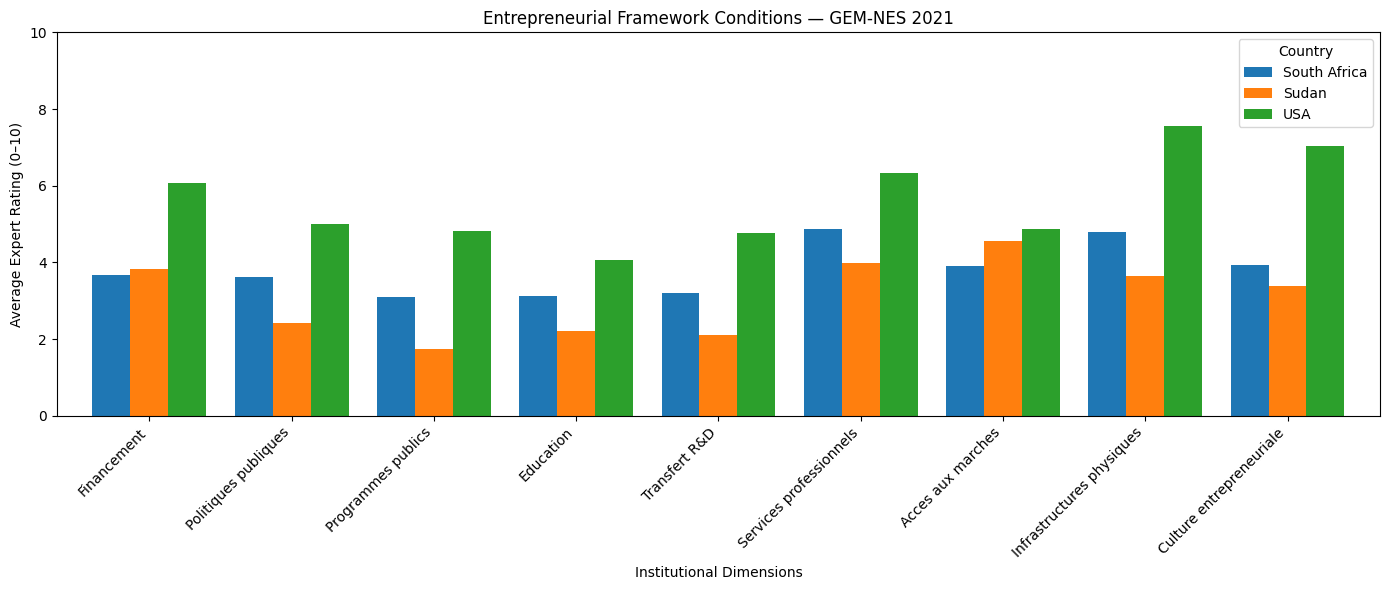

In [23]:
import matplotlib.pyplot as plt

scores.T.plot(
    kind="bar",
    figsize=(14, 6),
    width=0.8
)

plt.title("Entrepreneurial Framework Conditions — GEM-NES 2021")
plt.xlabel("Institutional Dimensions")
plt.ylabel("Average Expert Rating (0–10)")
plt.ylim(0, 10)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Country")
plt.tight_layout()
plt.show()

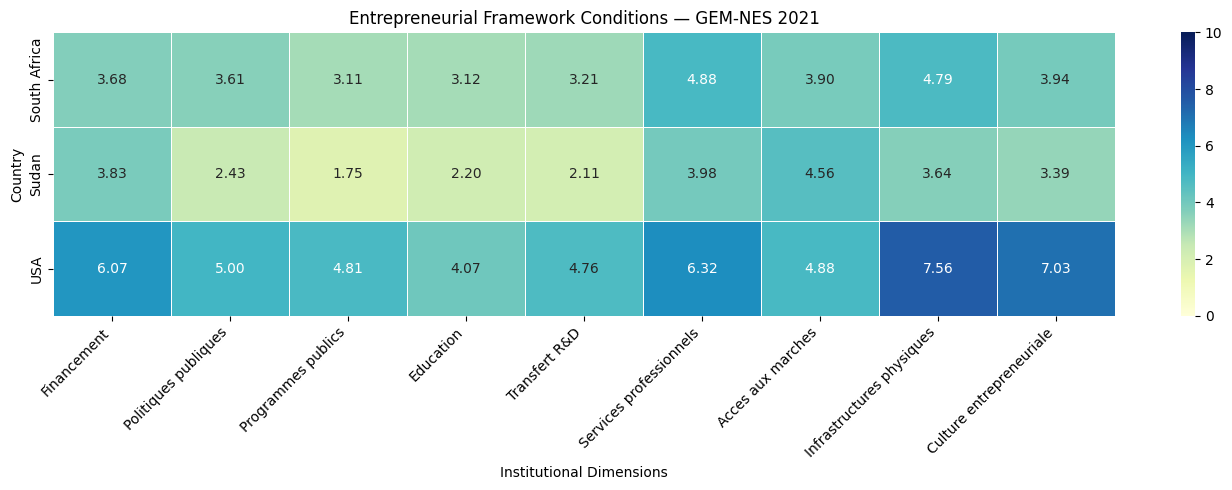

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

sns.heatmap(
    scores,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=10,
    linewidths=0.5
)

plt.title("Entrepreneurial Framework Conditions — GEM-NES 2021")
plt.xlabel("Institutional Dimensions")
plt.ylabel("Country")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
effectifs = df_3pays.groupby("Pays")[
    list(dimensions.values())
].count()

display(effectifs)

,Financement,Politiques publiques,Programmes publics,Education,Transfert R&D,Services professionnels,Acces aux marches,Infrastructures physiques,Culture entrepreneuriale
Pays,,,,,,,,,
South Africa,37,37,37,37,37,37,37,37,37
Sudan,36,36,36,36,36,36,36,36,36
USA,46,46,42,42,41,41,43,42,43


In [26]:
for code, nom in dimensions.items():
    colonnes = [
        col for col in colonnes_efc
        if col.startswith(f"NES21_{code}")
    ]

    complets = (
        df_3pays.groupby("Pays")[colonnes]
        .apply(lambda x: x.notna().all(axis=1).sum())
    )

    print(f"\n{nom}")
    print(complets)


Financement
Pays
South Africa    28
Sudan           21
USA             26
dtype: int64

Politiques publiques
Pays
South Africa    29
Sudan           29
USA             30
dtype: int64

Programmes publics
Pays
South Africa    33
Sudan           32
USA             22
dtype: int64

Education
Pays
South Africa    36
Sudan           32
USA             36
dtype: int64

Transfert R&D
Pays
South Africa    31
Sudan           34
USA             23
dtype: int64

Services professionnels
Pays
South Africa    33
Sudan           34
USA             36
dtype: int64

Acces aux marches
Pays
South Africa    30
Sudan           22
USA             34
dtype: int64

Infrastructures physiques
Pays
South Africa    30
Sudan           31
USA             33
dtype: int64

Culture entrepreneuriale
Pays
South Africa    35
Sudan           36
USA             43
dtype: int64


In [27]:
import numpy as np

for code, nom in dimensions.items():
    colonnes = [
        col for col in colonnes_efc
        if col.startswith(f"NES21_{code}")
    ]

    minimum = int(np.ceil(len(colonnes) * 0.5))

    df_3pays[nom + "_50"] = (
        df_3pays[colonnes]
        .mean(axis=1)
        .where(
            df_3pays[colonnes].count(axis=1) >= minimum
        )
    )

scores_50 = df_3pays.groupby("Pays")[
    [nom + "_50" for nom in dimensions.values()]
].mean()

scores_50.columns = list(dimensions.values())

display(scores_50.round(2))

,Financement,Politiques publiques,Programmes publics,Education,Transfert R&D,Services professionnels,Acces aux marches,Infrastructures physiques,Culture entrepreneuriale
Pays,,,,,,,,,
South Africa,3.68,3.61,3.11,3.15,3.21,4.88,3.90,4.86,3.94
Sudan,3.83,2.43,1.75,2.20,2.11,3.98,4.56,3.64,3.39
USA,6.06,4.95,4.15,4.07,4.58,6.32,4.99,7.56,7.03


In [28]:
effectifs_50 = df_3pays.groupby("Pays")[
    [nom + "_50" for nom in dimensions.values()]
].count()

effectifs_50.columns = list(dimensions.values())

display(effectifs_50)

,Financement,Politiques publiques,Programmes publics,Education,Transfert R&D,Services professionnels,Acces aux marches,Infrastructures physiques,Culture entrepreneuriale
Pays,,,,,,,,,
South Africa,37,37,37,36,37,37,37,36,37
Sudan,36,36,36,36,36,36,36,36,36
USA,45,45,33,42,37,41,42,42,43


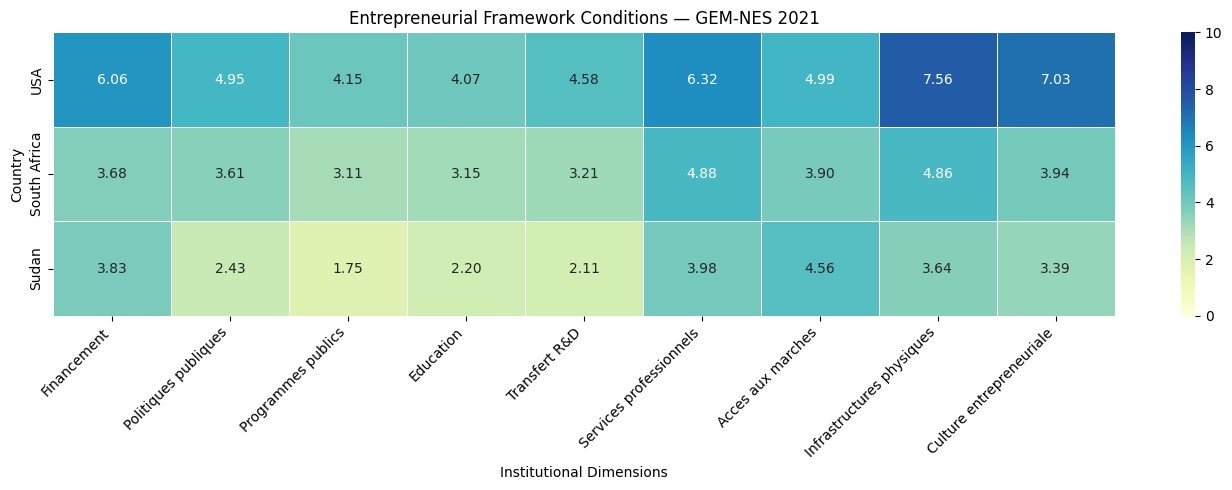

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

ordre = ["USA", "South Africa", "Sudan"]

plt.figure(figsize=(14, 5))

sns.heatmap(
    scores_50.loc[ordre],
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    vmin=0,
    vmax=10,
    linewidths=0.5
)

plt.title("Entrepreneurial Framework Conditions — GEM-NES 2021")
plt.xlabel("Institutional Dimensions")
plt.ylabel("Country")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("GEM_NES_2021_Heatmap_Final.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [37]:
dashboard_data = (
    scores_50
    .reset_index()
    .melt(
        id_vars="Pays",
        var_name="Dimension",
        value_name="Score"
    )
)

display(dashboard_data.head(10))

,Pays,Dimension,Score
0,South Africa,Financement,3.683934
1,Sudan,Financement,3.834652
2,USA,Financement,6.056341
3,South Africa,Politiques publiques,3.611969
4,Sudan,Politiques publiques,2.425430
5,USA,Politiques publiques,4.954444
6,South Africa,Programmes publics,3.108752
7,Sudan,Programmes publics,1.749339
8,USA,Programmes publics,4.151732
9,South Africa,Education,3.148148


In [36]:
from IPython.display import display

display(dashboard_data.head(10))

,Pays,Dimension,Score
0,South Africa,Financement,3.683934
1,Sudan,Financement,3.834652
2,USA,Financement,6.056341
3,South Africa,Politiques publiques,3.611969
4,Sudan,Politiques publiques,2.425430
5,USA,Politiques publiques,4.954444
6,South Africa,Programmes publics,3.108752
7,Sudan,Programmes publics,1.749339
8,USA,Programmes publics,4.151732
9,South Africa,Education,3.148148


In [45]:
import plotly.express as px

fig = px.bar(
    dashboard_data,
    x="Dimension",
    y="Score",
    color="Pays",
    barmode="group",
    title="Entrepreneurial Framework Conditions — GEM-NES 2021",
    labels={
        "Dimension": "Institutional Dimensions",
        "Score": "Average Expert Rating (0–10)",
        "Pays": "Country"
    },
    category_orders={
        "Pays": ["USA", "South Africa", "Sudan"]
    },
    range_y=[0, 10]
)

fig.update_layout(
    width=1100,
    height=600,
    xaxis_tickangle=-45
)

fig.show()

In [40]:
translations = {
    "Financement": "Entrepreneurial Finance",
    "Politiques publiques": "Government Policies",
    "Programmes publics": "Government Programs",
    "Education": "Entrepreneurial Education",
    "Transfert R&D": "R&D Transfer",
    "Services professionnels": "Professional Services",
    "Acces aux marches": "Market Access",
    "Infrastructures physiques": "Physical Infrastructure",
    "Culture entrepreneuriale": "Entrepreneurial Culture"
}

dashboard_data["Dimension"] = (
    dashboard_data["Dimension"].replace(translations)
)

dashboard_data["Pays"] = (
    dashboard_data["Pays"].replace({
        "South Africa": "South Africa",
        "Sudan": "Sudan",
        "USA": "United States"
    })
)

import plotly.express as px

fig = px.bar(
    dashboard_data,
    x="Dimension",
    y="Score",
    color="Pays",
    barmode="group",
    title="Entrepreneurial Framework Conditions — GEM-NES 2021",
    labels={
        "Dimension": "Institutional Dimensions",
        "Score": "Average Expert Rating (0–10)",
        "Pays": "Country"
    },
    range_y=[0, 10]
)

fig.update_layout(
    height=650,
    xaxis_tickangle=-40,
    legend_title_text="Country",
    margin=dict(l=60, r=40, t=80, b=150)
)

fig.show()

In [41]:
scores_en = scores_50.rename(
    columns=translations
).rename(
    index={"USA": "United States"}
)

effectifs_en = effectifs_50.rename(
    columns=translations
).rename(
    index={"USA": "United States"}
)

print("Scores:", scores_en.shape)
print("Sample sizes:", effectifs_en.shape)
print("Dashboard data:", dashboard_data.shape)

Scores: (3, 9)
Sample sizes: (3, 9)
Dashboard data: (27, 3)


In [42]:
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import HTML, display

# Country order
countries = ["United States", "South Africa", "Sudan"]

# Interactive bar chart
bar = px.bar(
    dashboard_data,
    x="Dimension",
    y="Score",
    color="Pays",
    barmode="group",
    category_orders={"Pays": countries},
    labels={
        "Pays": "Country",
        "Dimension": "Institutional Dimension",
        "Score": "Average Expert Rating"
    }
)

bar.update_layout(
    title="Comparison of Entrepreneurial Framework Conditions",
    height=550,
    xaxis_tickangle=-35,
    yaxis_range=[0, 10],
    legend_title_text="Country"
)

# Interactive heatmap
heat = go.Figure(
    data=go.Heatmap(
        z=scores_en.loc[countries].values,
        x=scores_en.columns,
        y=countries,
        colorscale="YlGnBu",
        zmin=0,
        zmax=10,
        text=scores_en.loc[countries].round(2).values,
        texttemplate="%{text}",
        hovertemplate="%{y}<br>%{x}<br>Score: %{z:.2f}<extra></extra>"
    )
)

heat.update_layout(
    title="Institutional Conditions Heatmap",
    height=450,
    xaxis_tickangle=-35
)

# Sample size table
sample_table = go.Figure(
    data=[
        go.Table(
            header=dict(
                values=["Country"] + list(effectifs_en.columns)
            ),
            cells=dict(
                values=[
                    effectifs_en.index.tolist()
                ] + [
                    effectifs_en[col].tolist()
                    for col in effectifs_en.columns
                ]
            )
        )
    ]
)

sample_table.update_layout(
    title="Number of Experts by Institutional Dimension",
    height=300
)

# Combine charts into one HTML dashboard
html_content = f"""
<html>
<head>
<title>GEM-NES 2021 Entrepreneurial Ecosystems Dashboard</title>
<style>
body {{
    font-family: Arial, sans-serif;
    margin: 35px;
    background-color: #f5f7fb;
}}
h1, h2 {{
    color: #17365d;
}}
.section {{
    background: white;
    padding: 20px;
    margin-bottom: 25px;
    border-radius: 12px;
}}
</style>
</head>
<body>

<h1>Entrepreneurial Ecosystems: Comparative Dashboard</h1>
<p><b>Data source:</b> Global Entrepreneurship Monitor,
National Expert Survey (2021)</p>
<p><b>Countries:</b> United States, South Africa, Sudan</p>
<p><b>Experts surveyed:</b> 121</p>
<p><b>Method:</b> Mean expert ratings (0–10).
At least 50% of dimension items required per expert.</p>

<div class="section">
{bar.to_html(full_html=False, include_plotlyjs=True)}
</div>

<div class="section">
{heat.to_html(full_html=False, include_plotlyjs=False)}
</div>

<div class="section">
{sample_table.to_html(full_html=False, include_plotlyjs=False)}
</div>

</body>
</html>
"""

filename = "GEM_NES_2021_Interactive_Dashboard.html"

with open(filename, "w", encoding="utf-8") as f:
    f.write(html_content)

print("Dashboard created successfully:", filename)

Dashboard created successfully: GEM_NES_2021_Interactive_Dashboard.html


In [43]:
import os

filename = "GEM_NES_2021_Interactive_Dashboard.html"

print("Fichier trouvé :", os.path.exists(filename))

Fichier trouvé : True


In [46]:
from google.colab import files

files.download("GEM_NES_2021_Interactive_Dashboard.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>